before filtering: 24984
after filtering: 10718


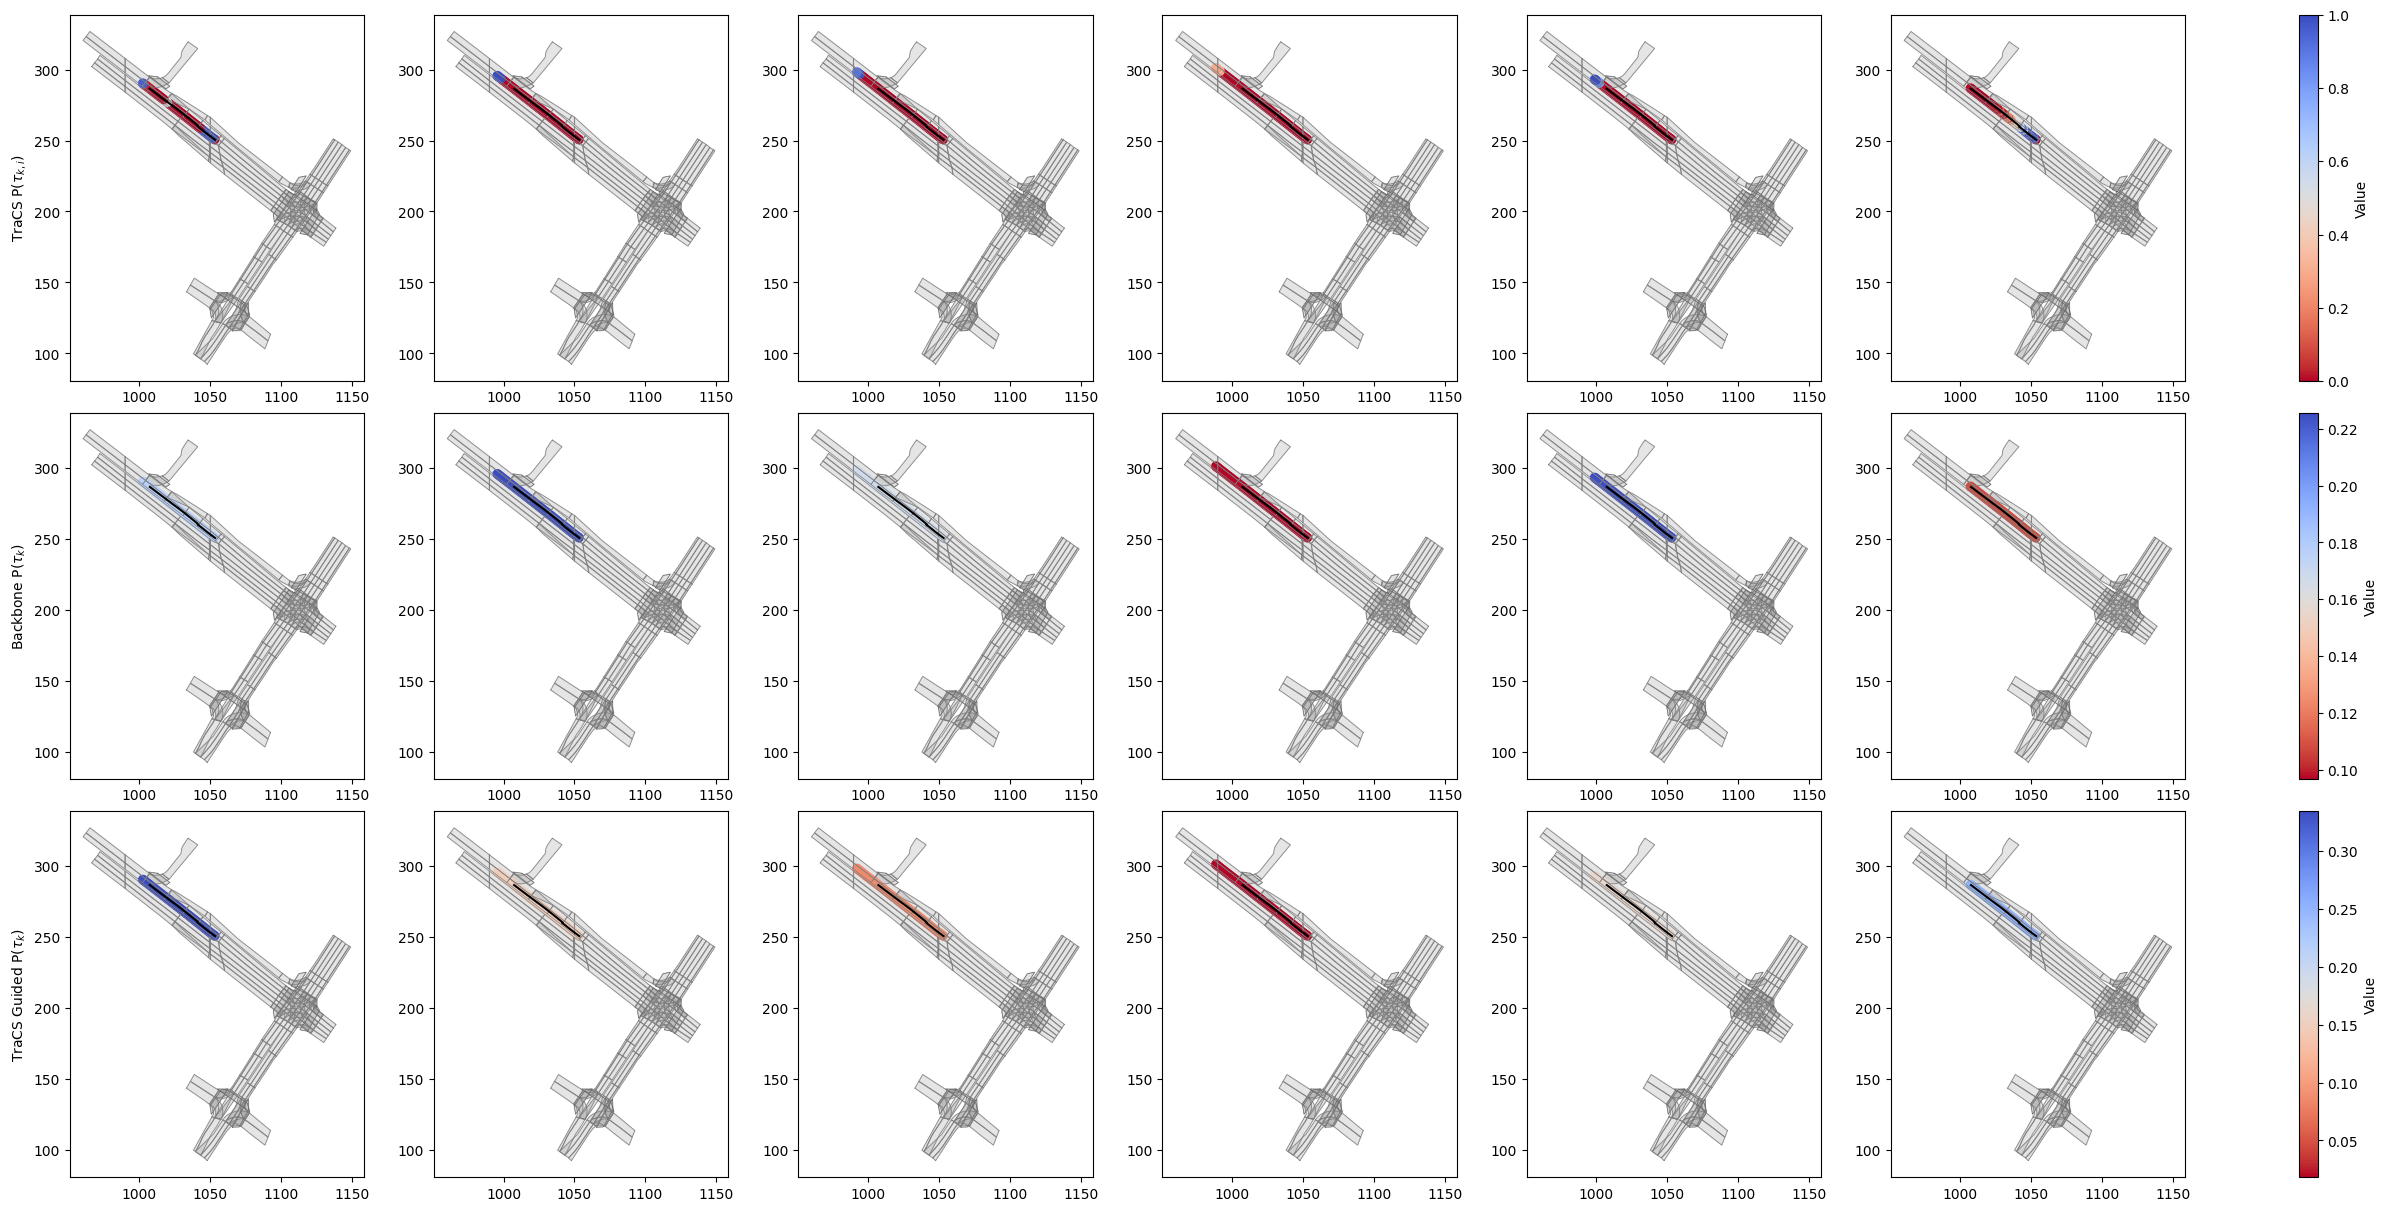

In [ ]:
from eval import tracs_rate_scenario, show_comparison_study
from pathlib import Path
import pandas as pd

def get_worst(metrics_path: str, n_head = 36):
    metrics_df = pd.read_parquet(metrics_path)
    print("before filtering:", len(metrics_df))
    metrics_df = metrics_df[(metrics_df["is_missed_prediction1"]) & (~metrics_df["is_missed_prediction6"])]
    print("after filtering:", len(metrics_df))
    return metrics_df.sort_values("brier_minADE6", ascending=False).head(n_head)

logic = """
distance(vehicle) <- source("/star_map/distance/vehicle", Density).
speed <- source("/sensors/speed", Number).

# Define three speed levels for city driving with corresponding safe distances
low_speed if speed < 20.
medium_speed if speed > 20 and speed < 40.
high_speed if speed > 40.

# Safe distance requirements for each speed level
safe_at_low if low_speed and distance(vehicle) > 5.
safe_at_medium if medium_speed and distance(vehicle) > 10.
safe_at_high if high_speed and distance(vehicle) > 20.

# Landscape: safe distance must be maintained according to speed level
landscape if safe_at_low.
landscape if safe_at_medium.
landscape if safe_at_high.

landscape -> target("/landscape").
"""

data_root = Path("/path/to/TraCS/data")
prediction_path = data_root / "DeMo_submission_translated_merged.parquet"
metrics_path = data_root / "DeMo_metrics.parquet"
trust = 1.0

scenario_id = get_worst(metrics_path).iloc[0]["scenario_id"]

scored_predictions = tracs_rate_scenario(
    scenario_id=scenario_id,
    logic=logic, 
    prediction_path=prediction_path,
    data_root=data_root,
    mode="test",
    trust=trust,
)

show_comparison_study(scored_predictions, data_root, "test", scenario_id)